# LifeGuard-RL XJTU charge-only RUL comparison

Test whether voltage-rise and taper timing make remaining useful life (RUL) estimates better for XJTU cells charged at 3C. The primary comparison is at cycle 100. Cycle 50 shows how the measurements perform earlier.

1. In **Kaggle CPU**, attach the previous SOH result ZIP or extracted **cycle_quality.csv** and **cycle_features.csv**. Attach **XJTU_labels.json** from BatteryLife v12.
2. Run all cells. The notebook uses the small cycle tables and reproduces the original held-out partitions.
3. Download **lifeguard_rul_charge_features_results.zip** with the error comparison, fold assignments, and predictions for each held-out cell.

[BatteryLife v12 release](https://zenodo.org/records/21149533) · [Charging-curve features in the XJTU study](https://doi.org/10.1038/s41467-024-48779-z)

In [30]:
INPUT_ROOT = None
SOH_RESULTS_PATH = None  # Optional path to one SOH ZIP or its extracted folder.
LABEL_PATH = None  # Optional path to the published XJTU label JSON.
OUTPUT_ROOT = None
SEED = 42

from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).expanduser().resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## Compare training scope and charging features

The original Ridge uses total charge history and is fitted on 2C and 3C cells. The first candidate uses the same charge history and fits on 3C cells. The second candidate uses medians for total charge, time from 4.0 to 4.1 V, and taper time in the last ten observed cycles. The third adds the change in total charge from the middle ten-cycle window to the last ten cycles. The middle window is cycles 41–50 for prediction at cycle 100 and 16–25 for prediction at cycle 50.

The outer test folds contain whole cells. Scaling and Ridge settings use training cells only. The 2C method remains the charge-rate median. Charge anomalies are flagged using earlier observations of the same cell and skipped in the histories. Verified discharge-capacity crossings supply EOL labels.

In [31]:
KEY = ["cell_id", "cycle"]
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
PILOT_EOLS = {"XJTU_2C_battery-7": 401, "XJTU_3C_battery-2": 291}
NOMINAL_AH = 2.0
EOL_CAPACITY_AH = 1.6
LANDMARKS = (50, 100)
OUTLIER_CELL = "XJTU_2C_battery-2"
OUTLIER_CYCLE = 390
HISTORY_SIZE = 10
MIN_FLAG_HISTORY = 5
MAD_MULTIPLIER = 6.0
# Floors keep small variations from being flagged when recent readings are nearly identical.
FLAG_FLOORS = {"prefix_charge_ah": 0.08, "charge_duration_s": 120.0, "taper_duration_s": 120.0}
CURVE_DURATIONS = ["rise_duration_4_0_to_4_1_s", "taper_duration_s"]
FEATURE_FIELDS = [*FLAG_FLOORS, "rise_duration_4_0_to_4_1_s"]
RESULT_ARCHIVES = ("lifeguard_soh_validation_results.zip", "lifeguard_soh_results.zip")


def unique_path(matches, description):
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Expected one {description}, found {len(matches)}. Set SOH_RESULTS_PATH or LABEL_PATH.")
    return matches[0]


def locate_inputs(root):
    if SOH_RESULTS_PATH is None:
        result = None
        for filename in RESULT_ARCHIVES:
            matches = list(root.rglob(filename))
            if matches:
                result = unique_path(matches, filename)
                break
        if result is None:
            directories = [
                p.parent for p in root.rglob("cycle_quality.csv")
                if (p.parent / "cycle_features.csv").is_file()
            ]
            result = unique_path(directories, "folder containing both SOH cycle tables")
    else:
        result = Path(SOH_RESULTS_PATH).expanduser().resolve()
    if LABEL_PATH is None:
        labels = unique_path(root.rglob("XJTU_labels.json"), "XJTU_labels.json")
    else:
        labels = Path(LABEL_PATH).expanduser().resolve()
    return result, labels


def load_cycle_tables(results):
    names = ("cycle_quality.csv", "cycle_features.csv")
    if results.is_dir():
        quality, features = (pd.read_csv(results / name) for name in names)
    else:
        with ZipFile(results) as archive:
            frames = []
            for name in names:
                matches = [member for member in archive.namelist() if PurePosixPath(member).name == name]
                member = unique_path(matches, f"{name} inside the SOH results ZIP")
                with archive.open(member) as stream:
                    frames.append(pd.read_csv(stream))
        quality, features = frames

    late_columns = {f"late_taper_{field}": field for field in FEATURE_FIELDS}
    if all(field in features.columns for field in late_columns):
        features = features.rename(columns=late_columns)
    quality = quality.loc[:, KEY + ["charge_rate_c", "discharge_capacity_ah"]].copy()
    features = features.loc[:, KEY + FEATURE_FIELDS].copy()
    for frame in (quality, features):
        if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
            raise ValueError("The cycle tables must have unique, complete cell and cycle keys.")
    if set(quality.cell_id) != set(FIXED_CELLS) or not quality.charge_rate_c.eq(quality.cell_id.map(FIXED_CELLS)).all():
        raise ValueError("Expected the 23 fixed-protocol XJTU cells and their documented charge rates.")
    joined = features.merge(quality[KEY], on=KEY, how="left", indicator=True, validate="one_to_one")
    if not joined["_merge"].eq("both").all():
        raise ValueError("Every feature row must have a matching quality row.")
    if set(features.cell_id) != set(FIXED_CELLS):
        raise ValueError("Every cell must have some exported late-taper features.")
    return quality.sort_values(KEY).reset_index(drop=True), features.sort_values(KEY).reset_index(drop=True)

In [32]:
def audit_eol(quality, labels):
    records = []
    for cell, frame in quality.groupby("cell_id", sort=True):
        cycles = frame.cycle.to_numpy()
        if not np.array_equal(cycles, np.arange(1, len(frame) + 1)):
            raise ValueError(f"{cell} must have consecutive cycle numbers beginning at 1.")
        capacity = frame.discharge_capacity_ah.to_numpy(dtype=float)
        valid = np.isfinite(capacity) & (capacity > 0)
        last = int(cycles[valid][-1]) if valid.any() else None
        crossings = cycles[valid & (capacity <= EOL_CAPACITY_AH)]
        event = int(crossings[0]) if crossings.size else None
        published = labels.get(f"{cell}.pkl")
        if not isinstance(published, int) or published < 1:
            raise ValueError(f"No valid published label for {cell}.")
        if not valid.all():
            status = "review_missing_discharge_capacity"
        elif event is None:
            status = "right_censored" if published > last else "review_label_without_crossing"
        else:
            status = "observed" if event == published else "review_label_mismatch"
        records.append({
            "cell_id": cell, "charge_rate_c": FIXED_CELLS[cell], "last_observed_cycle": last,
            "observed_eol_cycle": event, "published_eol_cycle": published, "event_status": status,
        })
    result = pd.DataFrame(records)
    for column in ("last_observed_cycle", "observed_eol_cycle"):
        result[column] = result[column].astype("Int64")
    return result


def flag_charge_traces(features):
    by_cell = []
    for _, frame in features.groupby("cell_id", sort=False):
        frame = frame.sort_values("cycle").copy()
        marks = []
        for feature, floor in FLAG_FLOORS.items():
            values = frame[feature]
            valid = np.isfinite(values) & (values.ge(0) if feature == "taper_duration_s" else values.gt(0))
            # The shift keeps the current reading out of its own reference window.
            prior = values.where(valid).shift().rolling(HISTORY_SIZE, min_periods=MIN_FLAG_HISTORY)
            center = prior.median()
            mad = prior.apply(lambda window: np.nanmedian(np.abs(window - np.nanmedian(window))), raw=True)
            limit = (MAD_MULTIPLIER * 1.4826 * mad).clip(lower=floor)
            frame[f"{feature}_prior_median"] = center
            frame[f"{feature}_deviation_limit"] = limit
            flag = f"{feature}_flag"
            frame[flag] = ~valid | (values.sub(center).abs() > limit)
            marks.append(flag)
        frame["trace_flagged"] = frame[marks].any(axis=1)
        frame["reference_ready"] = frame[[f"{k}_prior_median" for k in FLAG_FLOORS]].notna().all(axis=1)
        by_cell.append(frame)
    return pd.concat(by_cell, ignore_index=True)

In [33]:
def history_features(history, value, landmark):
    history = history.loc[history.cycle <= landmark, ["cycle", value]].dropna()
    quiet = history.loc[history.cycle <= 10, value]
    recent = history.loc[history.cycle > landmark - 10, value]
    trend = history.loc[history.cycle > landmark - 20]
    if len(quiet) < 5 or len(recent) < 5 or len(trend) < 10:
        return None
    x = trend.cycle.to_numpy(dtype=float)
    x = x - x.mean()
    level = trend[value].to_numpy(dtype=float)
    slope = float(np.dot(x, level - level.mean()) / np.dot(x, x))
    return [float(quiet.median()), float(recent.median()), slope]


STATS = ("initial_median", "recent_median", "recent_slope")
CHARGE = [f"charge_{name}" for name in STATS]
RECENT = ["recent_charge_ah", "recent_4_0_to_4_1_s", "recent_taper_s"]
CHARGE_CHANGE = "charge_change_ah"
TARGET = "observed_rul_cycles"
SHORT_LIFE_CYCLE = 200


def window_median(history, field, end):
    values = history.loc[history.cycle.between(end - 9, end), field].to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    return float(np.median(values)) if values.size >= 5 else np.nan


def charge_features(history, landmark):
    original = history_features(history, "prefix_charge_ah", landmark)
    if original is None:
        return None
    latest = [window_median(history, field, landmark) for field in ("prefix_charge_ah", *CURVE_DURATIONS)]
    middle = window_median(history, "prefix_charge_ah", landmark // 2)
    return {
        **dict(zip(CHARGE, original, strict=True)),
        **dict(zip(RECENT, latest, strict=True)),
        CHARGE_CHANGE: latest[0] - middle,
    }


def build_landmarks(flags, eol):
    kept = flags.loc[~flags.trace_flagged].copy()
    # Optional measurements are checked independently of the original charge features.
    valid_durations = np.isfinite(kept[CURVE_DURATIONS]) & kept[CURVE_DURATIONS].ge(0)
    kept[CURVE_DURATIONS] = kept[CURVE_DURATIONS].where(valid_durations)
    by_cell = {cell: frame for cell, frame in kept.groupby("cell_id")}
    rows, audit = [], []
    for cell in eol.itertuples(index=False):
        history = by_cell.get(cell.cell_id, kept.iloc[:0])
        for landmark in LANDMARKS:
            identity = {"cell_id": cell.cell_id, "charge_rate_c": cell.charge_rate_c, "landmark_cycle": landmark}
            status = cell.event_status
            if status == "observed":
                if cell.observed_eol_cycle <= landmark:
                    status = "event_at_or_before_landmark"
                else:
                    features = charge_features(history, landmark)
                    if features is None:
                        status = "missing_original_charge_history"
                    elif cell.charge_rate_c == 3 and not all(np.isfinite(features[name]) for name in (*RECENT, CHARGE_CHANGE)):
                        status = "missing_3c_feature_window"
                    else:
                        status = "eligible"
                        event = int(cell.observed_eol_cycle)
                        rows.append({
                            **identity, **features, "observed_eol_cycle": event, TARGET: event - landmark,
                        })
            audit.append({**identity, "landmark_status": status, "event_status": cell.event_status})
    data = pd.DataFrame(rows)
    membership = pd.DataFrame(audit)
    missing = membership.loc[membership.event_status.eq("observed") & ~membership.landmark_status.eq("eligible")]
    if not missing.empty:
        pairs = ", ".join(f"{row.cell_id} at {row.landmark_cycle} ({row.landmark_status})"
                          for row in missing.itertuples(index=False))
        raise ValueError(f"Attach complete charge tables to compare the same observed cells at both landmarks. {pairs}")
    return data, membership


def check_feature_windows():
    cycles = np.arange(1, 121)
    history = pd.DataFrame({
        "cycle": cycles,
        "prefix_charge_ah": 1.9 - cycles * 0.001,
        CURVE_DURATIONS[0]: cycles.astype(float),
        CURVE_DURATIONS[1]: cycles.astype(float) * 2,
    })
    for landmark in LANDMARKS:
        expected = charge_features(history, landmark)
        assert expected == charge_features(history.loc[history.cycle <= landmark], landmark)
        assert expected[RECENT[1]] == landmark - 4.5
        assert np.isclose(expected[CHARGE_CHANGE], -0.001 * (landmark - landmark // 2))
        changed = history.copy()
        changed.loc[changed.cycle > landmark, "prefix_charge_ah"] = 5.0
        assert expected == charge_features(changed, landmark)
    lost = history.loc[~history.cycle.between(41, 47)]
    assert np.isnan(charge_features(lost, 100)[CHARGE_CHANGE])


def check_causal_history():
    cycles = np.arange(1, 61)
    synthetic = pd.DataFrame({
        "cell_id": "test", "cycle": cycles,
        "prefix_charge_ah": np.where(cycles == 40, 1.90, 1.65),
        "charge_duration_s": 2500.0, "taper_duration_s": 600.0,
    })
    full = flag_charge_traces(synthetic)
    prefix = flag_charge_traces(synthetic.loc[synthetic.cycle <= 50])
    assert full.loc[full.cycle == 40, "trace_flagged"].item()
    assert not full.loc[full.cycle == 39, "trace_flagged"].item()
    pd.testing.assert_frame_equal(full.loc[full.cycle <= 50].reset_index(drop=True), prefix)
    values = history_features(full.loc[~full.trace_flagged], "prefix_charge_ah", 50)
    edited = full.copy()
    edited.loc[edited.cycle > 50, "prefix_charge_ah"] = 3.9
    assert values == history_features(edited.loc[~edited.trace_flagged], "prefix_charge_ah", 50)

In [34]:
PROTOCOL = "protocol_median"
ORIGINAL = "ridge_charge_history_pooled"
ONLY_3C = "ridge_3c_original_features"
LATE = "ridge_3c_recent_signals"
LATE_CHANGE = "ridge_3c_recent_signals_and_change"
CANDIDATES = {ONLY_3C: CHARGE, LATE: RECENT, LATE_CHANGE: [*RECENT, CHARGE_CHANGE]}
SHOW_MODELS = (PROTOCOL, ORIGINAL, *CANDIDATES)
ALPHAS = (0.1, 1.0, 10.0, 100.0)


def make_ridge(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def tune_ridge(train, columns, seed, pooled):
    partitioner = StratifiedKFold if pooled else KFold
    partition = partitioner(n_splits=3, shuffle=True, random_state=seed)
    folds = list(partition.split(train, train.charge_rate_c))
    scores = []
    for alpha in ALPHAS:
        errors = []
        for fit_idx, val_idx in folds:
            fit, val = train.iloc[fit_idx], train.iloc[val_idx]
            assert set(fit.cell_id).isdisjoint(val.cell_id)
            model = make_ridge(alpha).fit(fit[columns], fit[TARGET])
            estimate = np.maximum(model.predict(val[columns]), 0.0)
            errors.extend(np.abs(estimate - val[TARGET].to_numpy()))
        scores.append((float(np.mean(errors)), alpha))
    return min(scores, key=lambda score: (score[0], -score[1]))


def run_benchmark(data, eol):
    cells = eol[["cell_id", "charge_rate_c"]].sort_values("cell_id").reset_index(drop=True)
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(splitter.split(cells, cells.charge_rate_c))
    predictions, split_rows, tuning = [], [], []
    for landmark in LANDMARKS:
        rows = data.loc[data.landmark_cycle.eq(landmark)]
        if rows.empty or rows.cell_id.duplicated().any():
            raise ValueError(f"Expected one prediction row per eligible cell at cycle {landmark}.")
        for fold, (train_idx, test_idx) in enumerate(folds, start=1):
            train = rows[rows.cell_id.isin(cells.iloc[train_idx].cell_id)]
            test = rows[rows.cell_id.isin(cells.iloc[test_idx].cell_id)]
            train_3c = train[train.charge_rate_c.eq(3)]
            test_3c = test[test.charge_rate_c.eq(3)]
            if train_3c.empty or test_3c.empty:
                raise ValueError(f"The 3C group is empty in the training or test set of fold {fold}.")
            assert set(train.cell_id).isdisjoint(test.cell_id)
            for role, frame in (("train", train), ("test", test)):
                split_rows.extend({"landmark_cycle": landmark, "fold": fold, "role": role, "cell_id": cell,
                                   "charge_rate_c": rate} for cell, rate in frame[["cell_id", "charge_rate_c"]].itertuples(index=False))

            def record(name, frame, values):
                estimates = frame[["cell_id", "landmark_cycle", "charge_rate_c", "observed_eol_cycle", TARGET]].copy()
                estimates["predicted_rul_cycles"] = values
                estimates["model"], estimates["fold"] = name, fold
                predictions.append(estimates)

            by_rate = train.groupby("charge_rate_c")[TARGET].median()
            record(PROTOCOL, test, test.charge_rate_c.map(by_rate).to_numpy())

            configurations = [(ORIGINAL, ["charge_rate_c", *CHARGE], train, test)]
            configurations.extend((name, columns, train_3c, test_3c) for name, columns in CANDIDATES.items())
            for name, columns, train_rows, test_rows in configurations:
                score, alpha = tune_ridge(train_rows, columns, seed=SEED + landmark + fold, pooled=name == ORIGINAL)
                model = make_ridge(alpha).fit(train_rows[columns], train_rows[TARGET])
                record(name, test_rows, np.maximum(model.predict(test_rows[columns]), 0.0))
                tuning.append({"landmark_cycle": landmark, "fold": fold, "model": name, "alpha": alpha,
                               "inner_mae_cycles": score, "train_cells": len(train_rows), "test_cells": len(test_rows)})
        print(f"Cycle {landmark}  {len(rows)} observed cells, including {int(rows.charge_rate_c.eq(3).sum())} at 3C")
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(split_rows), pd.DataFrame(tuning)


def validate_predictions(data, predictions, split_rows):
    keys = ["cell_id", "landmark_cycle"]
    assert not data.duplicated(keys).any() and set(predictions.model) == set(SHOW_MODELS)
    assert np.isfinite(predictions.predicted_rul_cycles).all()
    test = split_rows.loc[split_rows.role == "test", keys + ["fold"]]
    train = split_rows.loc[split_rows.role == "train", keys + ["fold"]]
    assert not test.duplicated(keys).any() and test.merge(train, on=keys + ["fold"]).empty
    for model, frame in predictions.groupby("model"):
        cohort = data.loc[data.charge_rate_c.eq(3)] if model in CANDIDATES else data
        expected = pd.MultiIndex.from_frame(cohort[keys]).sort_values()
        actual = pd.MultiIndex.from_frame(frame[keys]).sort_values()
        assert actual.equals(expected)
        assert len(frame.merge(test, on=keys + ["fold"], validate="one_to_one")) == len(frame)

In [35]:
PRIMARY_LANDMARK = 100
MODEL_NAMES = {
    PROTOCOL: "Protocol median",
    ORIGINAL: "Original Ridge with pooled 2C and 3C",
    ONLY_3C: "3C Ridge with original features",
    LATE: "3C Ridge with recent signals",
    LATE_CHANGE: "3C Ridge with recent signals and change",
}


def score_predictions(predictions):
    signed = predictions.predicted_rul_cycles - predictions[TARGET]
    errors = predictions.assign(error_cycles=signed, absolute_error_cycles=signed.abs())
    rows = []
    for (landmark, rate, model), frame in errors.groupby(["landmark_cycle", "charge_rate_c", "model"]):
        short = frame[frame.observed_eol_cycle.le(SHORT_LIFE_CYCLE)]
        worst = frame.loc[frame.absolute_error_cycles.idxmax()]
        rows.append({
            "landmark_cycle": landmark, "charge_rate_c": rate, "model": model, "cells": len(frame),
            "mae_cycles": frame.absolute_error_cycles.mean(),
            "rmse_cycles": np.sqrt(frame.error_cycles.pow(2).mean()),
            "worst_error_cycles": worst.absolute_error_cycles, "worst_cell": worst.cell_id,
            "bias_cycles": frame.error_cycles.mean(), "largest_overprediction_cycles": max(0.0, frame.error_cycles.max()),
            "short_life_cells": len(short), "short_life_mae_cycles": short.absolute_error_cycles.mean(),
            "short_life_largest_overprediction_cycles": max(0.0, short.error_cycles.max()) if len(short) else np.nan,
        })
    metrics = pd.DataFrame(rows).sort_values(["landmark_cycle", "charge_rate_c", "mae_cycles", "model"])
    return errors, metrics


def assess_candidates(metrics):
    primary = metrics[metrics.landmark_cycle.eq(PRIMARY_LANDMARK) & metrics.charge_rate_c.eq(3)].set_index("model")
    reference = primary.loc[ORIGINAL]
    records = []
    tolerance = 1e-9
    for name in CANDIDATES:
        candidate = primary.loc[name]
        checks = {
            "same_test_coverage": bool(candidate.cells == reference.cells and candidate.short_life_cells == reference.short_life_cells),
            "mean_error_lower": bool(candidate.mae_cycles < reference.mae_cycles - tolerance),
            "worst_error_lower": bool(candidate.worst_error_cycles < reference.worst_error_cycles - tolerance),
            "short_life_error_no_higher": bool(candidate.short_life_mae_cycles <= reference.short_life_mae_cycles + tolerance),
        }
        records.append({
            "model": name, **checks, "passes": all(checks.values()),
            "mae_delta_cycles": candidate.mae_cycles - reference.mae_cycles,
            "worst_error_delta_cycles": candidate.worst_error_cycles - reference.worst_error_cycles,
            "short_life_mae_delta_cycles": candidate.short_life_mae_cycles - reference.short_life_mae_cycles,
        })
    decisions = pd.DataFrame(records)
    passing = decisions[decisions.passes].sort_values(["mae_delta_cycles", "worst_error_delta_cycles", "model"])
    return decisions, ORIGINAL if passing.empty else passing.iloc[0].model


def write_summary(path, eol, metrics, decisions, choice):
    count = eol.event_status.value_counts()
    lines = [
        "# LifeGuard-RL RUL from charging features",
        "",
        f"**{len(eol)} cells** audited · **{count.get('observed', 0)}** verified 80% SOH crossings.",
        "",
        "The primary decision uses predictions at cycle 100 for 3C cells. Cycle 50 provides the earlier comparison.",
        "All models use charging data available by the observation cycle. The measured discharge defines the EOL label.",
        "",
    ]
    for row in eol[eol.event_status.ne("observed")].itertuples(index=False):
        lines.append(f"- {row.cell_id} has status {row.event_status.replace('_', ' ')} and is excluded from supervised scoring.")
    lines.extend([
        "", "## 3C held-out errors", "",
        "| Observation cycle | Model | Cells | MAE | Worst absolute error | MAE for EOL ≤200 |",
        "| ---: | --- | ---: | ---: | ---: | ---: |",
    ])
    for row in metrics[metrics.charge_rate_c.eq(3)].itertuples(index=False):
        lines.append(
            f"| {row.landmark_cycle} | {MODEL_NAMES[row.model]} | {row.cells} | {row.mae_cycles:.2f} | "
            f"{row.worst_error_cycles:.2f} | {row.short_life_mae_cycles:.2f} |"
        )
    reference = metrics.loc[
        metrics.landmark_cycle.eq(PRIMARY_LANDMARK) & metrics.charge_rate_c.eq(3) & metrics.model.eq(ORIGINAL)
    ].iloc[0]
    median_2c = metrics.loc[
        metrics.landmark_cycle.eq(PRIMARY_LANDMARK) & metrics.charge_rate_c.eq(2) & metrics.model.eq(PROTOCOL)
    ].iloc[0]
    lines.extend([
        "", "Errors are in cycles. The short-life group is evaluated using the observed EOL cycle.",
        "",
        f"The rerun of the original 3C baseline at cycle 100 has MAE **{reference.mae_cycles:.2f}** "
        f"and worst error **{reference.worst_error_cycles:.2f}** cycles.",
        "",
        "## Benchmark decision", "",
        f"- 3C uses **{MODEL_NAMES[choice]}** for this benchmark. {int(decisions.passes.sum())} of {len(decisions)} candidates "
        "reduced both mean and worst error at cycle 100 with no increase in short-life MAE.",
        f"- 2C keeps the protocol median. Its cycle-100 MAE is **{median_2c.mae_cycles:.2f}** cycles.",
        "",
        "This is a comparison on the existing XJTU folds. Any improvement needs confirmation on a separate cohort.",
        "",
    ])
    path.write_text("\n".join(lines), encoding="utf-8")


def plot_primary_errors(predictions, choice, output):
    rows = predictions.loc[predictions.landmark_cycle.eq(PRIMARY_LANDMARK) & predictions.charge_rate_c.eq(3)]
    base = rows.loc[rows.model.eq(ORIGINAL)].sort_values(TARGET)
    x = np.arange(len(base))
    fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
    ax.plot(x, base[TARGET], color="black", marker="o", label="Observed RUL")
    ax.plot(x, base.predicted_rul_cycles, marker=".", linestyle="--", label="Original Ridge")
    if choice != ORIGINAL:
        chosen = base[["cell_id"]].merge(rows.loc[rows.model.eq(choice), ["cell_id", "predicted_rul_cycles"]],
                                        on="cell_id", validate="one_to_one")
        ax.plot(x, chosen.predicted_rul_cycles, marker=".", label=MODEL_NAMES[choice])
    ax.set_xticks(x, labels=base.cell_id.str.replace("XJTU_3C_battery-", "", regex=False))
    ax.set(xlabel="3C cell number, ordered by observed RUL", ylabel="RUL (cycles)", title="Held-out RUL at cycle 100")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
    fig.savefig(output, dpi=150)
    plt.close(fig)


def package_results(output, destination):
    staged = output.parent / "rul_pending.zip"
    with ZipFile(staged, "w", compression=ZIP_DEFLATED) as archive:
        for file in sorted(output.iterdir()):
            if file.is_file():
                archive.write(file, arcname=file.name)
    staged.replace(destination)

Reading cycle tables from /kaggle/input/datasets/sakibrayhanyeasin/result
Cycle 50  22 observed cells, including 15 at 3C
Cycle 100  22 observed cells, including 15 at 3C


# LifeGuard-RL RUL from charging features

**23 cells** audited · **22** verified 80% SOH crossings.

The primary decision uses predictions at cycle 100 for 3C cells. Cycle 50 provides the earlier comparison.
All models use charging data available by the observation cycle. The measured discharge defines the EOL label.

- XJTU_2C_battery-4 has status right censored and is excluded from supervised scoring.

## 3C held-out errors

| Observation cycle | Model | Cells | MAE | Worst absolute error | MAE for EOL ≤200 |
| ---: | --- | ---: | ---: | ---: | ---: |
| 50 | 3C Ridge with recent signals and change | 15 | 20.45 | 56.99 | 15.38 |
| 50 | 3C Ridge with recent signals | 15 | 21.05 | 64.77 | 16.39 |
| 50 | 3C Ridge with original features | 15 | 24.41 | 63.05 | 19.88 |
| 50 | Original Ridge with pooled 2C and 3C | 15 | 25.10 | 58.67 | 20.91 |
| 50 | Protocol median | 15 | 56.30 | 155.50 | 132.00 |
| 100 | 3C Ridge with original features | 15 | 21.49 | 59.89 | 21.68 |
| 100 | Original Ridge with pooled 2C and 3C | 15 | 21.94 | 52.85 | 21.90 |
| 100 | 3C Ridge with recent signals | 15 | 22.10 | 44.33 | 18.69 |
| 100 | 3C Ridge with recent signals and change | 15 | 22.30 | 44.42 | 21.24 |
| 100 | Protocol median | 15 | 56.30 | 155.50 | 132.00 |

Errors are in cycles. The short-life group is evaluated using the observed EOL cycle.

The rerun of the original 3C baseline at cycle 100 has MAE **21.94** and worst error **52.85** cycles.

## Benchmark decision

- 3C uses **Original Ridge with pooled 2C and 3C** for this benchmark. 0 of 3 candidates reduced both mean and worst error at cycle 100 with no increase in short-life MAE.
- 2C keeps the protocol median. Its cycle-100 MAE is **9.00** cycles.

This is a comparison on the existing XJTU folds. Any improvement needs confirmation on a separate cohort.


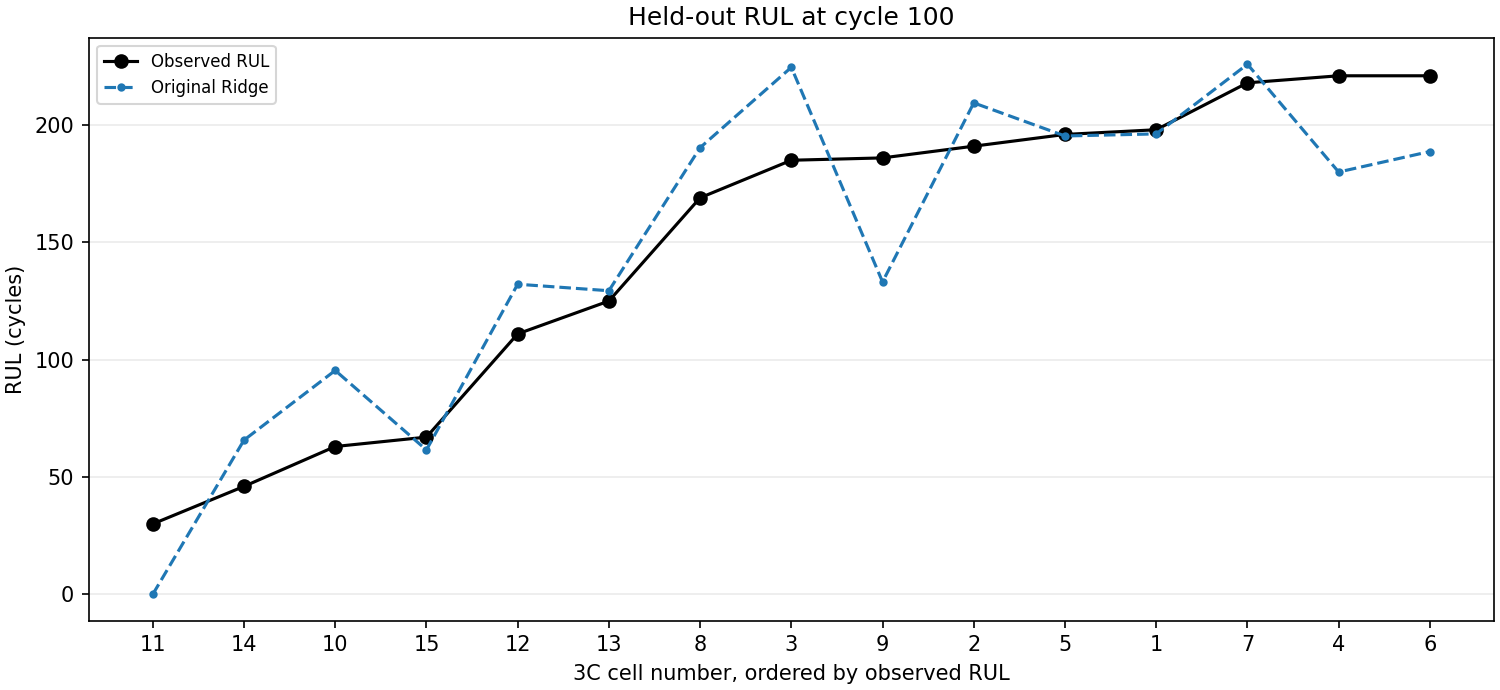

Download lifeguard_rul_charge_features_results.zip from the notebook output.


In [36]:
check_causal_history()
check_feature_windows()
soh_path, label_path = locate_inputs(INPUT_ROOT)
print(f"Reading cycle tables from {soh_path}")
quality, features = load_cycle_tables(soh_path)
labels = json.loads(label_path.read_text(encoding="utf-8"))
eol = audit_eol(quality, labels)
pilots = eol.set_index("cell_id").loc[list(PILOT_EOLS)]
assert pilots.event_status.eq("observed").all() and pilots.observed_eol_cycle.to_dict() == PILOT_EOLS
flags = flag_charge_traces(features)
data, landmark_audit = build_landmarks(flags, eol)
with threadpool_limits(limits=1):
    predictions, splits, tuning = run_benchmark(data, eol)
validate_predictions(data, predictions, splits)
scored, metrics = score_predictions(predictions)
decision, choice = assess_candidates(metrics)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_rul_charge_features_results.zip"
config = {
    "dataset": "BatteryLife v12", "dataset_doi": "10.5281/zenodo.21149533", "soh_input": soh_path.name,
    "seed": SEED, "nominal_capacity_ah": NOMINAL_AH, "eol_capacity_ah": EOL_CAPACITY_AH,
    "landmarks": list(LANDMARKS), "primary_landmark": PRIMARY_LANDMARK, "short_life_cycle": SHORT_LIFE_CYCLE,
    "ridge_alphas": list(ALPHAS), "candidate_columns": CANDIDATES,
    "charge_flag_history": HISTORY_SIZE, "charge_flag_min_history": MIN_FLAG_HISTORY,
    "charge_flag_mad_multiplier": MAD_MULTIPLIER, "charge_flag_floors": FLAG_FLOORS,
    "chosen_3c_model": choice, "chosen_2c_model": PROTOCOL,
    "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_rul_charge_", dir=OUTPUT_ROOT) as directory:
    output = Path(directory) / "results"
    output.mkdir()
    for filename, table in (
        ("eol_audit.csv", eol), ("landmark_audit.csv", landmark_audit), ("landmark_features.csv", data),
        ("rul_predictions.csv", scored), ("rul_metrics.csv", metrics), ("cell_splits.csv", splits),
        ("ridge_parameters.csv", tuning), ("model_selection.csv", decision),
    ):
        table.to_csv(output / filename, index=False)
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output / "summary.md", eol, metrics, decision, choice)
    plot_primary_errors(scored, choice, output / "rul_cycle_100.png")
    package_results(output, destination)
    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "rul_cycle_100.png")))

print(f"Download {destination.name} from the notebook output.")